[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/15_gmm_em.ipynb)

# 15 · Gaussian Mixtures & EM: Clustering With Probabilities

**Part 2 — Classical unsupervised learning** · Notebook 15 of 27

k-means (notebook 14) hands every point to exactly one cluster and pretends all clusters are round and equally spread. A **Gaussian mixture model** (GMM) relaxes both: it says the data came from a few Gaussian "sources", each with its own center, shape, and share of the data, and it reports for every point the **probability** that it came from each source.

Fitting that model introduces one of the most important algorithms in machine learning: **expectation–maximization (EM)**. EM handles any model with **hidden variables** (here, the unknown source of each point) by alternating between guessing the hidden variables and refitting the model. We'll derive it, animate it, prove why it never makes things worse, and see that k-means is EM's hard-edged special case. The same lower-bound idea returns, almost unchanged, as the ELBO of variational autoencoders (notebook 23).

**What you'll learn**

1. Density estimation: from one Gaussian to a mixture
2. The GMM as a generative story with a hidden label
3. Why maximum likelihood is hard here
4. EM: guess the labels softly, refit, repeat
5. EM from scratch, animated in 1-D and 2-D
6. **Why EM works**: the lower bound (ELBO) and Jensen's inequality
7. k-means is "hard EM"
8. Practical issues: local optima, collapsing components, covariance types
9. Choosing the number of components: BIC and held-out likelihood
10. What a fitted GMM is good for: soft clusters, densities, new samples
11. EM beyond Gaussians: the two-coin problem

*Course map: CX 4240 lectures 15–16 (density estimation pipeline, MLE of a Gaussian, GMM prior/class-conditional/marginal, connection to Gaussian naive Bayes, EM, k-means as hard GMM, GMM as soft k-means) and the GMM/EM exam pattern on the course cheat sheet.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy.stats import norm, multivariate_normal
from scipy.special import logsumexp
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from matplotlib.patches import Ellipse
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Density estimation: from one Gaussian to a mixture

CX 4240 frames unsupervised learning as three jobs: **density estimation**, clustering, and dimension reduction. Density estimation means learning the distribution $p(x)$ that generated the data. It follows the same pipeline as everything else in the course:

1. **Build a probabilistic model**
2. **Derive a loss** (maximum likelihood or MAP)
3. **Select an optimizer**

The simplest model is a single Gaussian. Its log-likelihood for data $x^1, \dots, x^m$ is

$$\ell(\mu, \Sigma) = \sum_{i=1}^m \log \mathcal{N}(x^i \mid \mu, \Sigma),$$

and setting the gradient to zero gives the familiar closed form (notebook 02): $\hat\mu = \frac1m\sum_i x^i$, $\hat\Sigma = \frac1m\sum_i (x^i - \hat\mu)(x^i - \hat\mu)^\top$.

But many datasets have more than one bump. Here's a stand-in for a classic: waiting times between eruptions of a geyser, which come in two flavors, short and long.

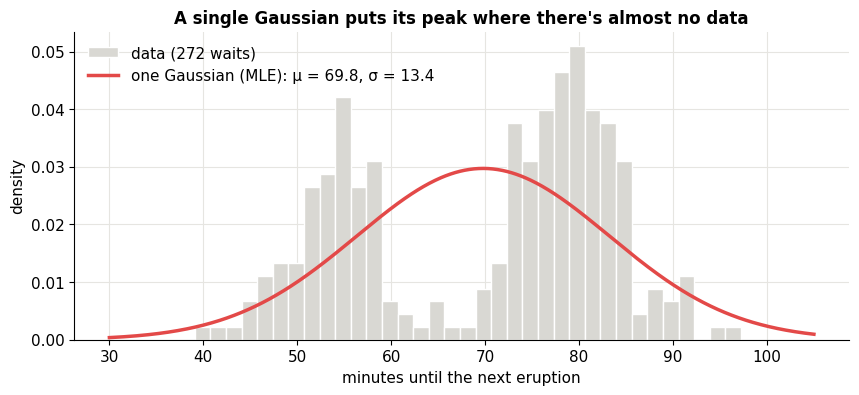

log-likelihood of the single Gaussian: -1092.3


In [2]:
r_ = np.random.default_rng(1)
wait = np.r_[r_.normal(54, 5.5, 100), r_.normal(80, 6.0, 172)]        # minutes; two kinds of eruption
xs = np.linspace(30, 105, 600)
mu1, sd1 = wait.mean(), wait.std()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(wait, bins=35, density=True, color=C["light"], edgecolor="white", label="data (272 waits)")
ax.plot(xs, norm.pdf(xs, mu1, sd1), color=C["red"], lw=2.5, label=f"one Gaussian (MLE): μ = {mu1:.1f}, σ = {sd1:.1f}")
ax.set(xlabel="minutes until the next eruption", ylabel="density", title="A single Gaussian puts its peak where there's almost no data")
ax.legend(); plt.show()
print(f"log-likelihood of the single Gaussian: {norm.logpdf(wait, mu1, sd1).sum():.1f}")

One Gaussian is forced to be a single symmetric bump, so it centers itself in the valley between the two real modes. The fix is to **mix** several Gaussians:

$$p(x) = \sum_{k=1}^{K} \pi_k\, \mathcal{N}(x \mid \mu_k, \Sigma_k), \qquad \pi_k \ge 0,\;\; \sum_k \pi_k = 1.$$

The **mixing weights** $\pi_k$ say what share of the data each component accounts for. 🎚️ **Build a two-component mixture by hand** and try to beat the single Gaussian's log-likelihood:

In [3]:
def mixture_by_hand(pi1=0.5, mu_a=50.0, mu_b=75.0, sigma=8.0):
    pis, mus = np.array([pi1, 1 - pi1]), np.array([mu_a, mu_b])
    comp = pis[:, None] * norm.pdf(xs[None, :], mus[:, None], sigma)
    ll = np.log((pis[:, None] * norm.pdf(wait[None, :], mus[:, None], sigma)).sum(0)).sum()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(wait, bins=35, density=True, color=C["light"], edgecolor="white")
    ax.plot(xs, comp[0], "--", color=C["blue"], label=f"π₁·N(μ₁ = {mu_a:.0f}, σ)"); ax.plot(xs, comp[1], "--", color=C["orange"], label=f"π₂·N(μ₂ = {mu_b:.0f}, σ)")
    ax.plot(xs, comp.sum(0), color=C["ink"], lw=2.5, label="mixture p(x)")
    ax.set(xlabel="minutes", ylabel="density", ylim=(0, 0.06), title=f"log-likelihood = {ll:.1f}   (single Gaussian: {norm.logpdf(wait, mu1, sd1).sum():.1f})")
    ax.legend(loc="upper left"); plt.show()

interact(mixture_by_hand, pi1=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="π₁"),
         mu_a=FloatSlider(value=50, min=35, max=100, step=1, description="μ₁"),
         mu_b=FloatSlider(value=75, min=35, max=100, step=1, description="μ₂"),
         sigma=FloatSlider(value=8, min=2, max=20, step=0.5, description="σ (shared)"));

Getting close to the best fit by hand takes some fiddling with four knobs. The rest of this notebook is about an algorithm that turns all the knobs for us, including a separate covariance for each component.

---
## 2. The GMM as a generative story with a hidden label

A mixture is easiest to understand as a **recipe for generating data** (CX lecture 15):

1. **Pick a component** $z \in \{1, \dots, K\}$ with probabilities $\pi$: the *class mixture prior* $p(z = k) = \pi_k$.
2. **Draw the point** from that component's Gaussian: the *class-conditional distribution* $p(x \mid z = k) = \mathcal{N}(x \mid \mu_k, \Sigma_k)$.

Summing out $z$ gives the *marginal distribution*, which is exactly the mixture formula: $p(x) = \sum_k p(z{=}k)\,p(x \mid z{=}k)$.

The label $z$ is a **hidden** (latent) variable: it was used to generate each point, but we never see it. In 2-D:

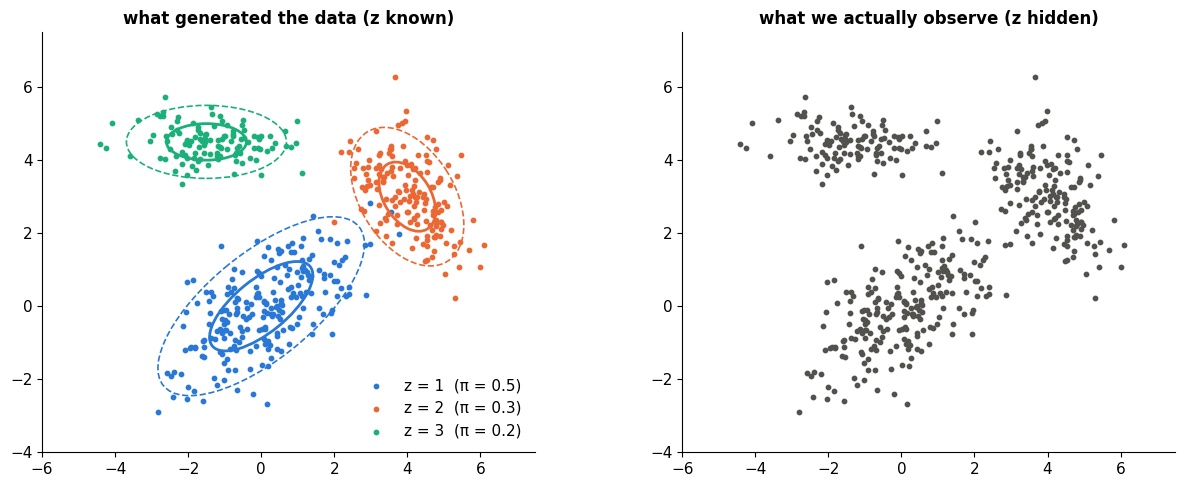

In [4]:
true_pi = np.array([0.5, 0.3, 0.2])
true_mu = np.array([[0.0, 0.0], [4.0, 3.0], [-1.5, 4.5]])
true_S = np.array([[[2.0, 1.2], [1.2, 1.5]], [[0.6, -0.3], [-0.3, 0.9]], [[1.2, 0.0], [0.0, 0.25]]])
r_ = np.random.default_rng(0); m = 500
z_true = r_.choice(3, size=m, p=true_pi)
X = np.array([r_.multivariate_normal(true_mu[k], true_S[k]) for k in z_true])
cols = [C["blue"], C["orange"], C["aqua"], C["violet"], C["magenta"], C["yellow"]]

def ellipse(ax, mu, S, color, n_std=(1, 2), **kw):
    """Draw the 1σ and 2σ contours of a 2-D Gaussian."""
    vals, vecs = np.linalg.eigh(S)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for s in n_std:
        ax.add_patch(Ellipse(mu, 2 * s * np.sqrt(vals[1]), 2 * s * np.sqrt(vals[0]), angle=angle,
                             fill=False, color=color, lw=2 if s == 1 else 1.2, ls="-" if s == 1 else "--", **kw))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k in range(3):
    axes[0].scatter(*X[z_true == k].T, s=10, color=cols[k], label=f"z = {k + 1}  (π = {true_pi[k]})")
    ellipse(axes[0], true_mu[k], true_S[k], cols[k])
axes[0].set(title="what generated the data (z known)", aspect="equal"); axes[0].legend(loc="lower right")
axes[1].scatter(*X.T, s=10, color=C["muted"]); axes[1].set(title="what we actually observe (z hidden)", aspect="equal")
for ax in axes: ax.set(xlim=(-6, 7.5), ylim=(-4, 7.5)); ax.grid(False)
fig.tight_layout(); plt.show()

If the labels **were** visible (left), fitting would be trivial: that's **Gaussian discriminant analysis / Gaussian naive Bayes** from notebook 09. Each $\pi_k$ is the fraction of points with label $k$, each $\mu_k$ and $\Sigma_k$ the mean and covariance of those points. CX 4240 makes exactly this connection.

> 🤔 **Question: So what's the difference between a GMM and Gaussian naive Bayes?** (CX lecture 15)
>
> The model is the same: a prior over classes times a Gaussian per class. (Strictly, "naive" Bayes uses diagonal covariances; a GMM usually allows full ones.) The difference is **what's observed**. In naive Bayes, the labels $y$ come with the training data, so we maximize $\sum_i \log p(x^i, y^i)$: a supervised problem with a closed-form answer. In a GMM, $z$ is never observed, so we maximize $\sum_i \log p(x^i) = \sum_i \log\sum_k p(x^i, z{=}k)$: an unsupervised problem with no closed form. The rest of the notebook is about that one $\sum_k$ inside the log.

---
## 3. Why maximum likelihood is hard here

The GMM log-likelihood is

$$\ell(\theta) = \sum_{i=1}^m \log\Big(\sum_{k=1}^K \pi_k\, \mathcal{N}(x^i \mid \mu_k, \Sigma_k)\Big), \qquad \text{subject to } \pi_k \ge 0,\;\textstyle\sum_k\pi_k = 1,\;\Sigma_k \succ 0.$$

For a single Gaussian the log cancels the exponential and we get a quadratic. Here the log sits **outside a sum**, so nothing cancels, and setting gradients to zero gives equations where each parameter depends on all the others. No closed form exists. Two more complications:

- **Many maxima.** Swapping the labels of two components gives exactly the same likelihood (*label switching*), so every good solution appears $K!$ times. There are also genuinely different local maxima.
- **Constraints.** Gradient ascent must keep $\pi$ on the simplex and every $\Sigma_k$ positive definite. CX 4240's verdict on stochastic gradient: *"plausible but tedious."*

Let's look at the landscape in the simplest case: the 1-D geyser data, two components with known weights and spread, and only the two means unknown:

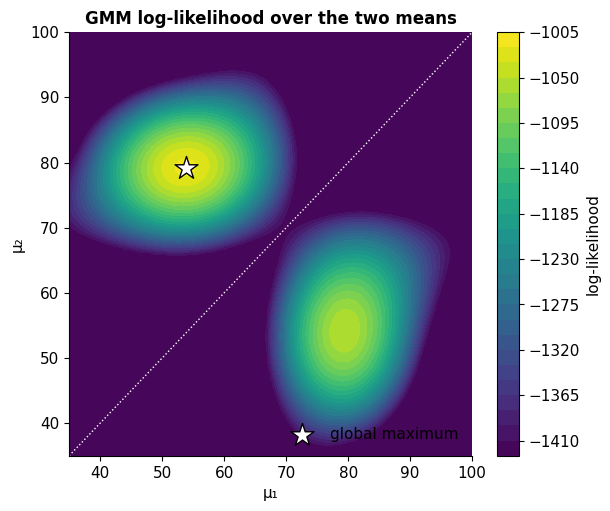

In [5]:
grid = np.linspace(35, 100, 160)
M1, M2 = np.meshgrid(grid, grid)
LL = np.zeros_like(M1)
for i in range(len(grid)):
    for j in range(len(grid)):
        LL[i, j] = np.log(0.37 * norm.pdf(wait, M1[i, j], 6) + 0.63 * norm.pdf(wait, M2[i, j], 6)).sum()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cs = ax.contourf(M1, M2, np.maximum(LL, LL.max() - 400), levels=30, cmap="viridis"); plt.colorbar(cs, label="log-likelihood")
best = np.unravel_index(LL.argmax(), LL.shape)
ax.scatter(M1[best], M2[best], marker="*", s=300, color="white", edgecolor="k", label="global maximum")
ax.plot(grid, grid, color="white", ls=":", lw=1)
ax.set(xlabel="μ₁", ylabel="μ₂", title="GMM log-likelihood over the two means"); ax.legend(loc="lower right")
plt.show()

Even with only two free parameters the surface has **two peaks**: the global maximum (μ₁ ≈ 54, μ₂ ≈ 80) and a lower one with the labels swapped (since we fixed π₁ = 0.37 for the *smaller* group, putting μ₁ on the big group is worse but still a local maximum). Along the diagonal (μ₁ = μ₂) the mixture collapses to a single Gaussian. A gradient method started in the wrong corner climbs the wrong hill. EM shares this weakness, which is why we restart it from several starting points.

---
## 4. EM: guess the labels softly, refit, repeat

The hard part is that we don't know $z$. The easy part is everything else: *if* we knew $z$, fitting is closed-form (section 2); *if* we knew the parameters, Bayes' rule would tell us how likely each $z$ is. EM alternates between the two (CX lecture 15):

**E-step (expectation): guess the labels with the current model.** For each point $i$ and component $k$, compute the posterior probability that $i$ came from $k$, called the **responsibility**:

$$\gamma_{ik} = p(z^i = k \mid x^i, \theta) = \frac{\pi_k\,\mathcal{N}(x^i \mid \mu_k, \Sigma_k)}{\sum_{j=1}^K \pi_j\,\mathcal{N}(x^i \mid \mu_j, \Sigma_j)}.$$

This is exactly the posterior a Gaussian Bayes classifier computes (notebook 09). It's a *soft* label: each row of $\gamma$ sums to 1.

**M-step (maximization): refit each component as if the soft labels were real**, with each point counting $\gamma_{ik}$ toward component $k$. Let $N_k = \sum_i \gamma_{ik}$ be the component's *effective size*. Then

$$\pi_k = \frac{N_k}{m}, \qquad \mu_k = \frac{1}{N_k}\sum_i \gamma_{ik}\, x^i, \qquad \Sigma_k = \frac{1}{N_k}\sum_i \gamma_{ik}\,(x^i - \mu_k)(x^i - \mu_k)^\top.$$

These are the naive-Bayes formulas with counts replaced by weighted counts. Repeat until the log-likelihood stops improving.

> 🤔 **Question: The rows of γ sum to 1. Do the columns?** (the cheat sheet's "exam trap")
>
> No. Each **row** sums to 1 because each point's responsibilities are a probability distribution over components: $\sum_k \gamma_{ik} = 1$. Each **column** sums to $N_k = \sum_i \gamma_{ik}$, the effective number of points in component $k$, which can be anything between 0 and $m$. The columns sum to $m$ in total, which is why $\pi_k = N_k/m$ automatically satisfies $\sum_k \pi_k = 1$.

---
## 5. EM from scratch

Two numerical details matter in practice. Densities in high dimensions underflow to zero, so we work with **log-densities** and normalize with the log-sum-exp trick: $\log\sum_j e^{a_j} = a^* + \log\sum_j e^{a_j - a^*}$ with $a^* = \max_j a_j$. And we add a tiny ridge to each covariance so it can't become singular (section 8 shows why).

In [6]:
def log_gauss(X, mu, S):
    """log N(x | mu, S) for every row of X, via a Cholesky factor (stable, no explicit inverse)."""
    d = X.shape[1]; L = np.linalg.cholesky(S)
    z = np.linalg.solve(L, (X - mu).T)                         # whitened residuals
    return -0.5 * (z ** 2).sum(0) - np.log(np.diag(L)).sum() - 0.5 * d * np.log(2 * np.pi)

def e_step(X, pi, mu, S):
    logp = np.column_stack([np.log(pi[k]) + log_gauss(X, mu[k], S[k]) for k in range(len(pi))])   # log π_k N(x_i | ...)
    log_px = logsumexp(logp, axis=1)                           # log p(x_i), computed stably
    return np.exp(logp - log_px[:, None]), log_px.sum()        # responsibilities γ, total log-likelihood

def m_step(X, gamma, reg=1e-6):
    Nk = gamma.sum(0); pi = Nk / len(X)
    mu = (gamma.T @ X) / Nk[:, None]
    S = np.array([((gamma[:, k, None] * (X - mu[k])).T @ (X - mu[k])) / Nk[k] + reg * np.eye(X.shape[1]) for k in range(len(Nk))])
    return pi, mu, S

def em_gmm(X, K, init_mu, n_iter=200, tol=1e-6, history=False):
    pi = np.full(K, 1 / K); mu = np.array(init_mu, float); S = np.array([np.cov(X.T).reshape(X.shape[1], X.shape[1])] * K)
    lls, hist = [], []
    for t in range(n_iter):
        gamma, ll = e_step(X, pi, mu, S)
        lls.append(ll)
        if history: hist.append((pi.copy(), mu.copy(), S.copy(), gamma.copy(), ll))
        if t > 0 and abs(lls[-1] - lls[-2]) < tol * abs(lls[-2]): break
        pi, mu, S = m_step(X, gamma)
    return (pi, mu, S, gamma, np.array(lls), hist) if history else (pi, mu, S, gamma, np.array(lls))

### 1-D: the geyser

Start with deliberately poor guesses (both components on the left) and watch EM sort it out. The colored bars under the histogram show each point's responsibility for the orange component: the E-step's soft labels.

In [7]:
W = wait[:, None]
pi_, mu_, S_, g_, lls1, hist1 = em_gmm(W, 2, init_mu=[[40.0], [48.0]], history=True)
print(f"EM converged in {len(lls1)} iterations:  π = {pi_.round(3)},  μ = {mu_.ravel().round(1)},  σ = {np.sqrt(S_.ravel()).round(1)}")
print(f"log-likelihood: {lls1[-1]:.1f}  (single Gaussian: {norm.logpdf(wait, mu1, sd1).sum():.1f})")

frames1 = list(range(min(len(hist1), 25)))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
order_w = np.argsort(wait)
def frame1(t):
    ax.clear(); ax2.clear()
    pi, mu, S, gamma, ll = hist1[t]
    ax.hist(wait, bins=35, density=True, color=C["light"], edgecolor="white")
    comps = [pi[k] * norm.pdf(xs, mu[k, 0], np.sqrt(S[k, 0, 0])) for k in range(2)]
    ax.plot(xs, comps[0], "--", color=C["blue"]); ax.plot(xs, comps[1], "--", color=C["orange"]); ax.plot(xs, comps[0] + comps[1], color=C["ink"], lw=2.2)
    ax.scatter(wait, np.full_like(wait, -0.004), c=gamma[:, 1], cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("bo", [C["blue"], C["orange"]]),
               vmin=0, vmax=1, s=30, marker="|")
    ax.set(xlim=(30, 105), ylim=(-0.008, 0.07), xlabel="minutes", title=f"EM iteration {t}:  log-likelihood {ll:.1f}")
    ax2.plot(range(t + 1), [h[4] for h in hist1[:t + 1]], "o-", color=C["red"])
    ax2.set(xlim=(-0.5, len(frames1) - 0.5), ylim=(hist1[0][4] - 5, hist1[-1][4] + 5), xlabel="iteration", ylabel="log-likelihood", title="never decreases")
anim = animation.FuncAnimation(fig, frame1, frames=frames1, interval=500)
show_anim(anim)

EM converged in 21 iterations:  π = [0.367 0.633],  μ = [53.6 79.2],  σ = [4.7 5.6]
log-likelihood: -1011.0  (single Gaussian: -1092.3)


At first both components sit on the left, so the right-hand points are poorly explained and the orange component (slightly further right) takes **responsibility** for them. The first M-step throws orange far to the right and stretches it wide, and the log-likelihood jumps. Then something instructive happens: for about ten iterations, EM **crawls**. The two components overlap heavily, so the mixture looks almost like one broad Gaussian, and the responsibilities only sharpen a little each round (this region is close to a saddle point of the likelihood). Once the components separate enough, the feedback loop takes over (sharper responsibilities → better-separated components → sharper responsibilities) and the fit snaps onto the two modes. The log-likelihood (right) climbs throughout; it just doesn't climb at a constant pace.

### 2-D: three components with their own shapes

Now the 2-D data from section 2, starting from three random data points. Each point's color mixes the three component colors in proportion to its responsibilities, and the ellipses show each component's 1σ and 2σ contours.

In [8]:
init = X[np.random.default_rng(3).choice(m, 3, replace=False)]
pi2, mu2, S2, g2, lls2, hist2 = em_gmm(X, 3, init_mu=init, history=True)
sk = GaussianMixture(3, means_init=init, weights_init=np.full(3, 1 / 3), precisions_init=np.array([np.linalg.inv(np.cov(X.T))] * 3),
                     covariance_type="full", tol=1e-10, reg_covar=1e-6, max_iter=500).fit(X)
print(f"from scratch: log-likelihood {lls2[-1]:.3f} after {len(lls2)} iterations")
print(f"scikit-learn (same start):    {sk.score(X) * m:.3f}")

rgb = np.array([plt.matplotlib.colors.to_rgb(c) for c in cols[:3]])
show_t = sorted(set(np.unique(np.geomspace(1, len(hist2), 18).astype(int) - 1)))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
def frame2(t):
    ax.clear(); ax2.clear()
    pi, mu, S, gamma, ll = hist2[t]
    ax.scatter(*X.T, s=12, c=np.clip(gamma @ rgb, 0, 1))
    for k in range(3):
        ellipse(ax, mu[k], S[k], cols[k]); ax.scatter(*mu[k], marker="X", s=180, color=cols[k], edgecolor="k", zorder=5)
    ax.set(xlim=(-6, 7.5), ylim=(-4, 7.5), aspect="equal", title=f"EM iteration {t}   π = {np.round(pi, 2)}"); ax.grid(False)
    ax2.plot(range(t + 1), [h[4] for h in hist2[:t + 1]], color=C["red"])
    ax2.set(xlim=(0, len(hist2)), ylim=(hist2[0][4] - 20, hist2[-1][4] + 20), xlabel="iteration", ylabel="log-likelihood")
anim = animation.FuncAnimation(fig, frame2, frames=show_t, interval=550)
show_anim(anim)

from scratch: log-likelihood -1817.357 after 15 iterations
scikit-learn (same start):    -1817.357


Same answer as scikit-learn from the same start. The components start as copies of the overall covariance (big, round, overlapping), so early responsibilities are mushy (muddy in-between colors). As the components specialize, they **change shape**: the tilted ellipse for the big component, a flat one for the small top-left group. That's exactly what k-means couldn't do.

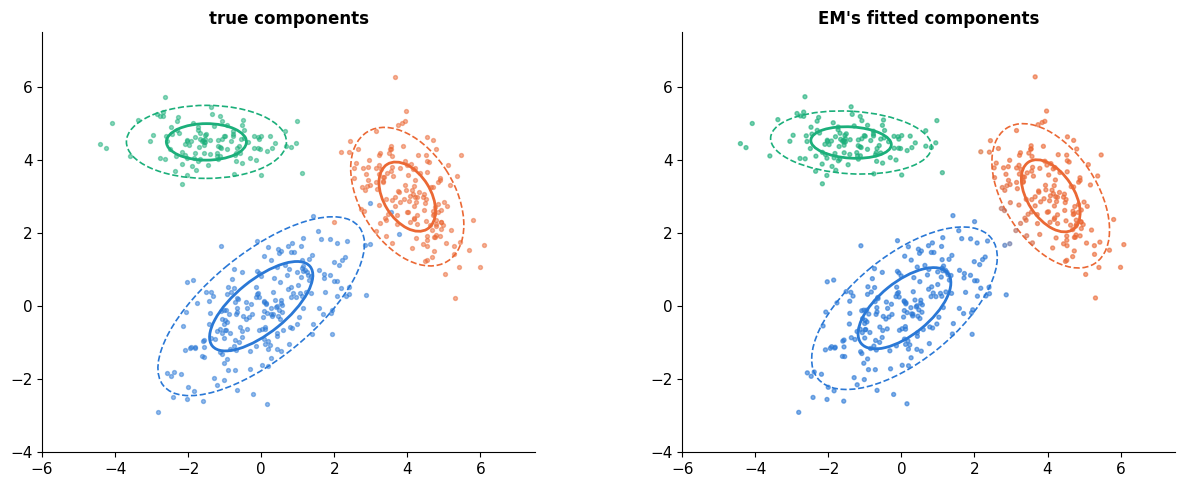

   true π  fitted π       true μ       fitted μ
0     0.5     0.445   (0.0, 0.0)  (0.08, -0.06)
1     0.3     0.321   (4.0, 3.0)   (4.09, 3.02)
2     0.2     0.234  (-1.5, 4.5)  (-1.38, 4.48)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k in range(3):
    ellipse(axes[0], true_mu[k], true_S[k], cols[k]); axes[0].scatter(*X[z_true == k].T, s=8, color=cols[k], alpha=0.5)
order_ = [np.argmin(((mu2 - true_mu[k]) ** 2).sum(1)) for k in range(3)]  # match learned components to true ones
for k, j in enumerate(order_):
    ellipse(axes[1], mu2[j], S2[j], cols[k])
axes[1].scatter(*X.T, s=8, c=np.clip(g2[:, order_] @ rgb, 0, 1), alpha=0.6)
axes[0].set(title="true components", aspect="equal"); axes[1].set(title="EM's fitted components", aspect="equal")
for ax in axes: ax.set(xlim=(-6, 7.5), ylim=(-4, 7.5)); ax.grid(False)
fig.tight_layout(); plt.show()
print(pd.DataFrame({"true π": true_pi, "fitted π": pi2[order_].round(3),
                    "true μ": [tuple(r) for r in true_mu], "fitted μ": [tuple(r) for r in mu2[order_].round(2)]}))

The fit recovers weights, centers, and shapes closely from 500 unlabeled points.

---
## 6. Why EM works: the lower bound

CX 4240 states that EM *"is actually optimizing a bound of the MLE, therefore it converges."* Let's derive that bound, because it explains everything: why the log-likelihood never decreases, what the E-step really computes, and (in notebook 23) how variational autoencoders are trained.

Take one point $x$ (sum over points at the end) and **any** distribution $q(z)$ over its hidden label. Multiply and divide by $q$ inside the log:

$$\log p(x \mid \theta) = \log\sum_z q(z)\,\frac{p(x, z \mid \theta)}{q(z)} \;\ge\; \sum_z q(z)\log\frac{p(x, z \mid \theta)}{q(z)} \;=:\; \mathcal{L}(q, \theta).$$

The inequality is **Jensen's**: log is concave, so the log of an average is at least the average of the logs. $\mathcal{L}$ is called the **evidence lower bound (ELBO)**. How loose is it? A few lines of algebra give the exact gap:

$$\log p(x \mid \theta) = \mathcal{L}(q, \theta) + \mathrm{KL}\big(q(z)\,\|\,p(z \mid x, \theta)\big).$$

KL divergence is never negative and equals zero only when the two distributions match. Now EM is **coordinate ascent on $\mathcal{L}$**:

- **E-step:** maximize $\mathcal{L}$ over $q$ with $\theta$ fixed. Since $\log p(x\mid\theta)$ doesn't depend on $q$, that means making the KL zero: set $q(z) = p(z \mid x, \theta)$, the posterior. Those are exactly the responsibilities $\gamma$. The bound now **touches** the log-likelihood at the current $\theta$.
- **M-step:** maximize $\mathcal{L}$ over $\theta$ with $q$ fixed. For a GMM, $\mathcal{L} = \sum_i\sum_k \gamma_{ik}\log\big(\pi_k\mathcal{N}(x^i\mid\mu_k,\Sigma_k)\big) + \text{const}$: a weighted *complete-data* log-likelihood, where the log sits next to the Gaussian, not outside a sum. Its maximizer is the weighted closed form of section 4.

So with $\theta_t$ the current parameters:

$$\log p(x\mid\theta_{t+1}) \;\ge\; \mathcal{L}(q_t, \theta_{t+1}) \;\ge\; \mathcal{L}(q_t, \theta_t) \;=\; \log p(x\mid\theta_t).$$

The first step holds because $\mathcal{L}$ is a lower bound everywhere, the second because the M-step maximized it, and the equality because the E-step made the bound tight. **The log-likelihood can never go down.** Let's see it for the geyser with only $\mu_2$ free:

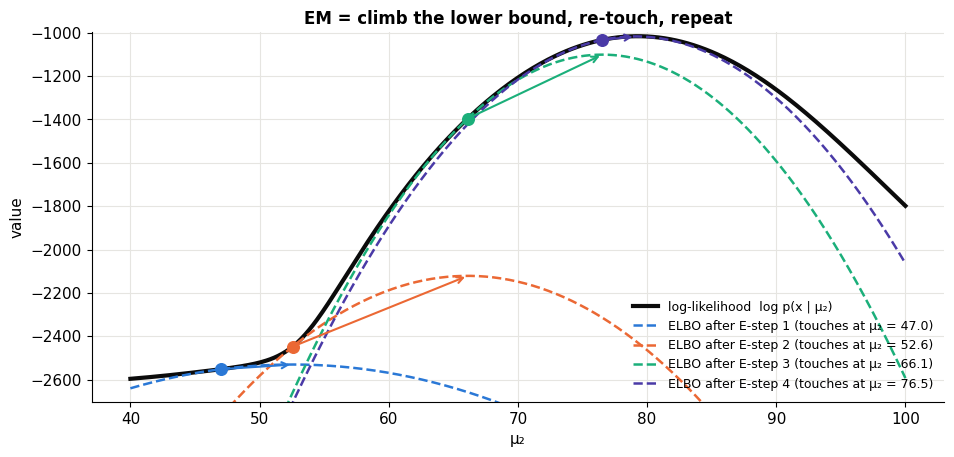

In [10]:
def ll_mu2(m2, m1=54.0, s=6.0, p=0.37):
    return np.log(p * norm.pdf(wait, m1, s) + (1 - p) * norm.pdf(wait, m2, s)).sum()

def elbo_curve(m2_grid, gamma, m1=54.0, s=6.0, p=0.37):
    """L(q, θ) as a function of μ2, with q fixed to responsibilities gamma."""
    out = []
    for m2 in m2_grid:
        lj = np.column_stack([np.log(p) + norm.logpdf(wait, m1, s), np.log(1 - p) + norm.logpdf(wait, m2, s)])
        out.append((gamma * (lj - np.log(np.clip(gamma, 1e-300, None)))).sum())
    return np.array(out)

g = np.linspace(40, 100, 400)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(g, [ll_mu2(v) for v in g], color=C["ink"], lw=3, label="log-likelihood  log p(x | μ₂)")
m2 = 47.0; pal = [C["blue"], C["orange"], C["aqua"], C["violet"]]
for t in range(4):
    lj = np.column_stack([np.log(0.37) + norm.logpdf(wait, 54, 6), np.log(0.63) + norm.logpdf(wait, m2, 6)])
    gamma = np.exp(lj - logsumexp(lj, axis=1, keepdims=True))   # E-step at the current μ₂
    bound = elbo_curve(g, gamma)
    ax.plot(g, bound, "--", color=pal[t], lw=1.8, label=f"ELBO after E-step {t + 1} (touches at μ₂ = {m2:.1f})")
    ax.scatter(m2, ll_mu2(m2), color=pal[t], s=70, zorder=5)
    m2_new = (gamma[:, 1] * wait).sum() / gamma[:, 1].sum()     # M-step: the bound's maximizer
    ax.annotate("", (m2_new, bound.max()), (m2, ll_mu2(m2)), arrowprops=dict(arrowstyle="->", color=pal[t], lw=1.5))
    m2 = m2_new
ax.set(ylim=(ll_mu2(47) - 150, ll_mu2(80) + 20), xlabel="μ₂", ylabel="value", title="EM = climb the lower bound, re-touch, repeat")
ax.legend(fontsize=9, loc="lower right"); plt.show()

Each dashed curve is the ELBO built by one E-step. It lies **below** the true log-likelihood everywhere and **touches** it at the current μ₂ (dot). The M-step jumps to the top of the dashed curve (arrow), which must be at least as high on the solid curve. Then a new E-step builds a new bound touching at the new point. The steps shrink as EM approaches the peak, which is also why EM can be slow near convergence.

> 🤔 **Question: The slide says EM optimizes an "upper bound". Is it upper or lower?**
>
> It depends on the sign convention. On the **log-likelihood** (which we maximize), the ELBO is a **lower** bound, as derived above. On the **negative** log-likelihood (the loss we'd minimize), the negative ELBO is an **upper** bound. Same statement, flipped sign. This "minorize, then maximize" pattern (or "majorize, then minimize" for losses) is called an **MM algorithm**, and EM is its most famous instance.

> 🤔 **Question: Does monotone improvement mean EM finds the maximum-likelihood estimate?**
>
> No: it guarantees the log-likelihood never decreases and (under mild conditions) converges to a **stationary point**, usually a local maximum. Which one depends on the start, just like k-means. Section 8 shows what can go wrong.

---
## 7. k-means is "hard EM"

CX 4240's summary: *k-means can be understood as hard GMM; GMM can be understood as soft k-means.* Here's the precise version. Take a GMM where every component has the same **fixed** covariance $\sigma^2 I$ and equal weights. The responsibilities become

$$\gamma_{ik} = \frac{\exp\big(-\|x^i - \mu_k\|^2 / 2\sigma^2\big)}{\sum_j \exp\big(-\|x^i - \mu_j\|^2 / 2\sigma^2\big)},$$

a softmax of negative squared distances with temperature $2\sigma^2$. As $\sigma \to 0$, the softmax turns into an argmax: each point gives responsibility 1 to its **nearest** center and 0 to the rest. That's k-means' assignment step, and the M-step (weighted mean with 0/1 weights) is k-means' update step. 🎚️ **Shrink σ** and watch soft assignments harden:

In [11]:
Xk, yk = make_blobs(300, centers=[(-2, 0), (2, 0.5), (0, 3)], cluster_std=1.0, random_state=2)
centers_k = np.array([[-2.2, -0.2], [2.1, 0.4], [0.1, 2.8]])
rgb3 = np.array([plt.matplotlib.colors.to_rgb(c) for c in cols[:3]])

def soft_to_hard(sigma=1.5):
    D2 = ((Xk[:, None, :] - centers_k[None]) ** 2).sum(-1)
    logits = -D2 / (2 * sigma ** 2)
    gamma = np.exp(logits - logsumexp(logits, axis=1, keepdims=True))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].scatter(*Xk.T, s=16, c=np.clip(gamma @ rgb3, 0, 1)); axes[0].scatter(*centers_k.T, marker="X", s=220, c=cols[:3], edgecolor="k")
    axes[0].set(aspect="equal", title=f"σ = {sigma:.2f}: responsibilities (mixed colors = uncertain)"); axes[0].grid(False)
    axes[1].hist(gamma.max(1), bins=np.linspace(1 / 3, 1, 30), color=C["violet"])
    axes[1].set(xlabel="largest responsibility of each point", ylabel="points", title=f"mean max-responsibility {gamma.max(1).mean():.2f}  (1.00 = k-means)")
    fig.tight_layout(); plt.show()

interact(soft_to_hard, sigma=FloatSlider(value=1.5, min=0.05, max=4.0, step=0.05, description="σ"));

Large σ: every point is shared, centers would all drift toward the global mean. Small σ: colors become pure and the histogram piles up at 1. So k-means is the σ → 0 limit of EM for an isotropic, equal-weight GMM, and its objective is (up to constants) the limit of that model's log-likelihood.

That relationship also tells us when GMMs do better: whenever clusters differ in **spread, shape, or size**, the cases where k-means failed in notebook 14:

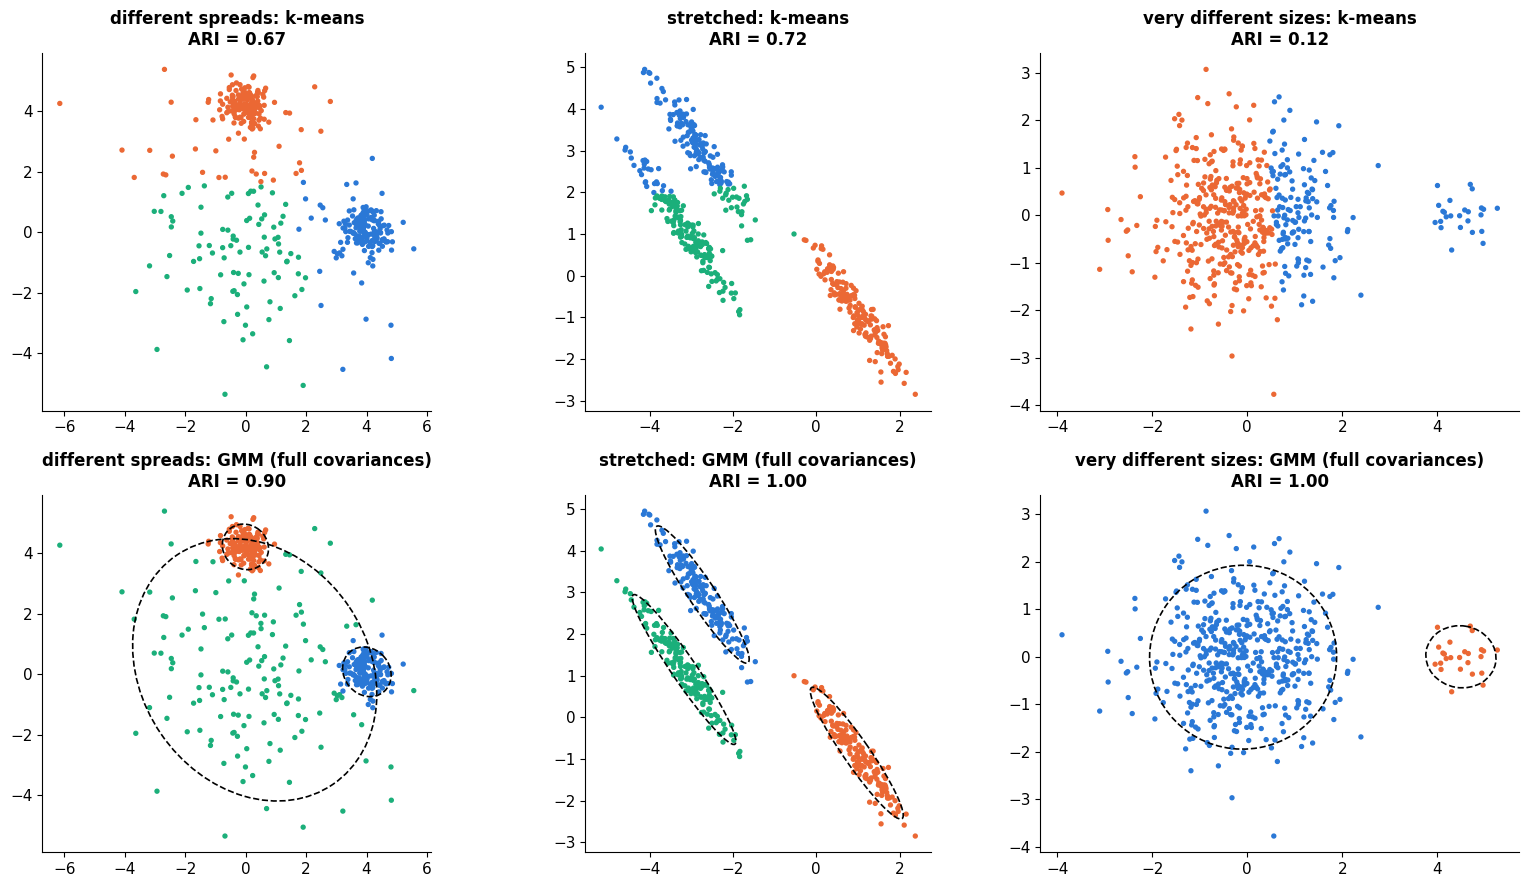

In [12]:
r_ = np.random.default_rng(0)
cases = {}
Xa, ya = make_blobs(450, centers=[(0, 0), (4, 0), (0, 4.2)], cluster_std=[2.2, 0.4, 0.4], random_state=1); cases["different spreads"] = (Xa, ya, 3)
Xs_, ys_ = make_blobs(500, centers=3, cluster_std=0.8, random_state=170); Xs_ = Xs_ @ np.array([[0.6, -0.64], [-0.41, 0.85]]); cases["stretched"] = (Xs_, ys_, 3)
Xu = np.vstack([r_.normal([0, 0], 1.0, (500, 2)), r_.normal([4.5, 0], 0.4, (25, 2))]); yu = np.r_[np.zeros(500, int), np.ones(25, int)]; cases["very different sizes"] = (Xu, yu, 2)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, (name, (X_, y_, k)) in enumerate(cases.items()):
    lab_km = KMeans(k, n_init=10, random_state=0).fit_predict(X_)
    gm = GaussianMixture(k, n_init=10, random_state=0).fit(X_); lab_gm = gm.predict(X_)
    for row, (lab, nm) in enumerate([(lab_km, "k-means"), (lab_gm, "GMM (full covariances)")]):
        ax = axes[row, col]; ax.scatter(*X_.T, s=8, c=[cols[l] for l in lab])
        if row == 1:
            for j in range(k): ellipse(ax, gm.means_[j], gm.covariances_[j], "k", n_std=(2,))
        ax.set(aspect="equal", title=f"{name}: {nm}\nARI = {adjusted_rand_score(y_, lab):.2f}"); ax.grid(False)
fig.tight_layout(); plt.show()

With a covariance and a weight per component, the GMM recovers the structures that defeated k-means. One caveat on the size example: we moved the small group a little further out than in notebook 14 (4.5 units from the big one instead of 3.2). k-means still splits the big cluster here, while the GMM gets it right. At 3.2, the small group sits inside the big one's tail, and the GMM recovers it only partly (ARI about 0.4). No method can sort out points that genuinely overlap, but the GMM at least reports them as uncertain. (It still can't do the interlocking moons: each component is one ellipse. Notebook 14's spectral clustering and DBSCAN handle those.)

---
## 8. Practical issues

### Local optima

Like k-means, EM converges to a local maximum that depends on the start. Twenty random starts on 2-D data with 6 components:

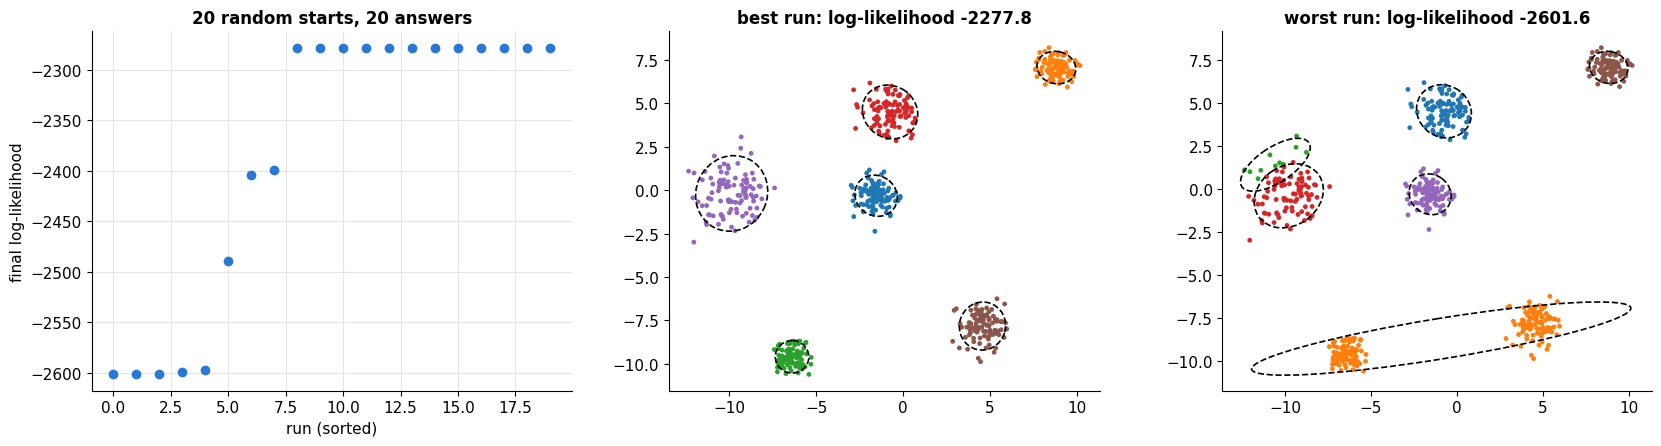

In [13]:
X6, y6 = make_blobs(600, centers=6, cluster_std=[0.5, 0.8, 0.6, 1.0, 0.5, 0.7], random_state=11)
final = []
for s in range(20):
    init_ = X6[np.random.default_rng(s).choice(len(X6), 6, replace=False)]
    out = em_gmm(X6, 6, init_mu=init_, n_iter=500)
    final.append((out[4][-1], out))
final.sort(key=lambda t: t[0])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(sorted([f[0] for f in final]), "o", color=C["blue"]); axes[0].set(xlabel="run (sorted)", ylabel="final log-likelihood", title="20 random starts, 20 answers")
for ax, (ll, (pi, mu, S, gam, lls)), nm in [(axes[1], final[-1], "best"), (axes[2], final[0], "worst")]:
    ax.scatter(*X6.T, s=6, c=[plt.get_cmap("tab10")(l) for l in gam.argmax(1)])
    for k in range(6): ellipse(ax, mu[k], S[k], "k", n_std=(2,))
    ax.set(aspect="equal", title=f"{nm} run: log-likelihood {ll:.1f}"); ax.grid(False)
fig.tight_layout(); plt.show()

The bad runs make the same kind of mistake as k-means: one wide component swallows two blobs while two components share another. Remedies are the same too: several restarts (`n_init` in scikit-learn), and initializing from a k-means solution (scikit-learn's default), which is itself typically seeded with k-means++.

### Collapsing components: the likelihood can go to infinity

Here's a failure k-means doesn't have. Put one component's mean exactly on a data point and shrink its variance. The Gaussian density at that point is $\frac{1}{\sqrt{2\pi}\sigma}$, which **blows up** as $\sigma \to 0$, while the other component keeps the rest of the likelihood finite. So the maximum likelihood of a GMM is **unbounded**: the "best" fit is a degenerate spike on a single point.

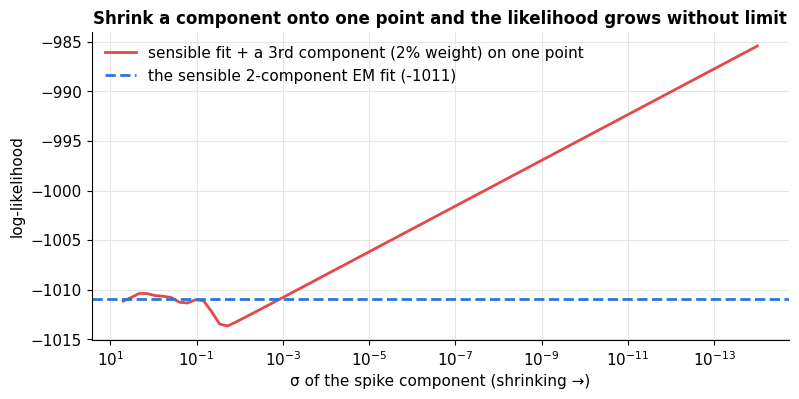

In [14]:
sig = np.geomspace(5, 1e-14, 80)
spike = wait[0]
good = pi_[0] * norm.pdf(wait, mu_[0, 0], np.sqrt(S_[0, 0, 0])) + pi_[1] * norm.pdf(wait, mu_[1, 0], np.sqrt(S_[1, 0, 0]))   # EM's fit from section 5
ll_spike = [np.log(0.98 * good + 0.02 * norm.pdf(wait, spike, s_)).sum() for s_ in sig]
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(sig, ll_spike, color=C["red"], label="sensible fit + a 3rd component (2% weight) on one point")
ax.invert_xaxis()
ax.axhline(lls1[-1], color=C["blue"], ls="--", label=f"the sensible 2-component EM fit ({lls1[-1]:.0f})")
ax.set(xlabel="σ of the spike component (shrinking →)", ylabel="log-likelihood", title="Shrink a component onto one point and the likelihood grows without limit")
ax.legend(); plt.show()

We took EM's good two-component fit and added a third component with 2% of the weight, centered exactly on one data point. Giving it 2% costs every point a little ($272\log 0.98 \approx -5.5$), but the density at that one point grows like $1/\sigma$, so each tenfold shrink of σ adds $\log 10 \approx 2.3$ to the log-likelihood. Below σ ≈ 10⁻³ the degenerate model beats the sensible one, and it keeps climbing forever. EM can drift into this, especially with many components, few points, or high dimensions. The standard fixes: add a small constant to every covariance's diagonal (scikit-learn's `reg_covar`, our `reg`), put a prior on the covariances (MAP instead of MLE, as in notebook 07), or detect components that collapse and re-initialize them.

### Covariance types: how much shape to allow

A full covariance in $d$ dimensions has $d(d+1)/2$ parameters per component, which gets expensive (and easy to overfit) quickly. Common restrictions:

| Type | Each component's covariance | Parameters for $K$ components in $d$ dims | Shapes |
|---|---|---|---|
| `full` | any $\Sigma_k$ | $K\,d(d+1)/2$ | tilted ellipses, own shape each |
| `tied` | one shared $\Sigma$ | $d(d+1)/2$ | same tilted ellipse for all |
| `diag` | diagonal $\Sigma_k$ | $K\,d$ | axis-aligned ellipses |
| `spherical` | $\sigma_k^2 I$ | $K$ | circles of different sizes |

(plus $Kd$ for the means and $K-1$ for the weights). `tied` gives linear boundaries between components, like LDA in notebook 09; `spherical` with equal sizes is the k-means model.

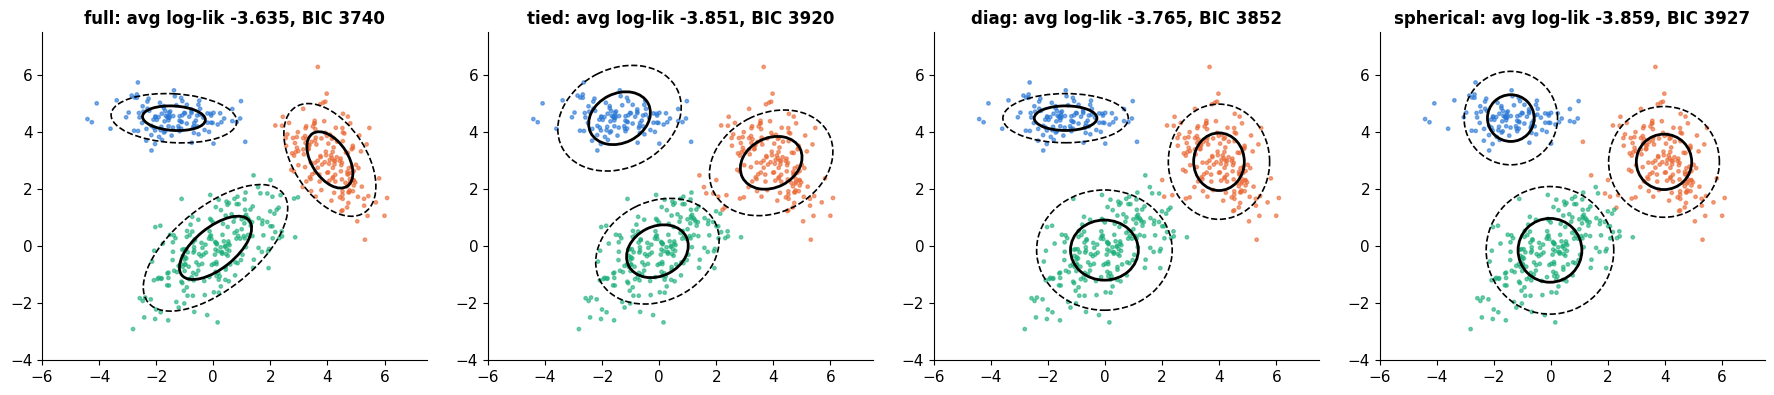

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, ct in zip(axes, ["full", "tied", "diag", "spherical"]):
    gm = GaussianMixture(3, covariance_type=ct, n_init=5, random_state=0).fit(X)
    covs = {"full": lambda g: g.covariances_, "tied": lambda g: [g.covariances_] * 3,
            "diag": lambda g: [np.diag(c) for c in g.covariances_], "spherical": lambda g: [c * np.eye(2) for c in g.covariances_]}[ct](gm)
    ax.scatter(*X.T, s=6, c=[cols[l] for l in gm.predict(X)], alpha=0.6)
    for k in range(3): ellipse(ax, gm.means_[k], covs[k], "k")
    ax.set(aspect="equal", xlim=(-6, 7.5), ylim=(-4, 7.5), title=f"{ct}: avg log-lik {gm.score(X):.3f}, BIC {gm.bic(X):.0f}"); ax.grid(False)
fig.tight_layout(); plt.show()

On this data, `full` fits best: the true components really are tilted and differently shaped. Which brings up the question of how to *choose* between models of different complexity.

---
## 9. Choosing the number of components

The training log-likelihood always improves with more components (more knobs, better fit), so we can't just maximize it. Two standard alternatives:

- **Held-out log-likelihood**: fit on training data, score the log-likelihood of validation data. Overfit models assign low density to new points. This is cross-validation (notebook 06) for densities.
- **BIC** (Bayesian information criterion): $\text{BIC} = -2\,\ell(\hat\theta) + p\log m$, where $p$ is the number of free parameters. Lower is better. The second term charges for complexity; it comes from an approximation to the Bayesian evidence. **AIC** uses $2p$ instead of $p\log m$ and penalizes less.

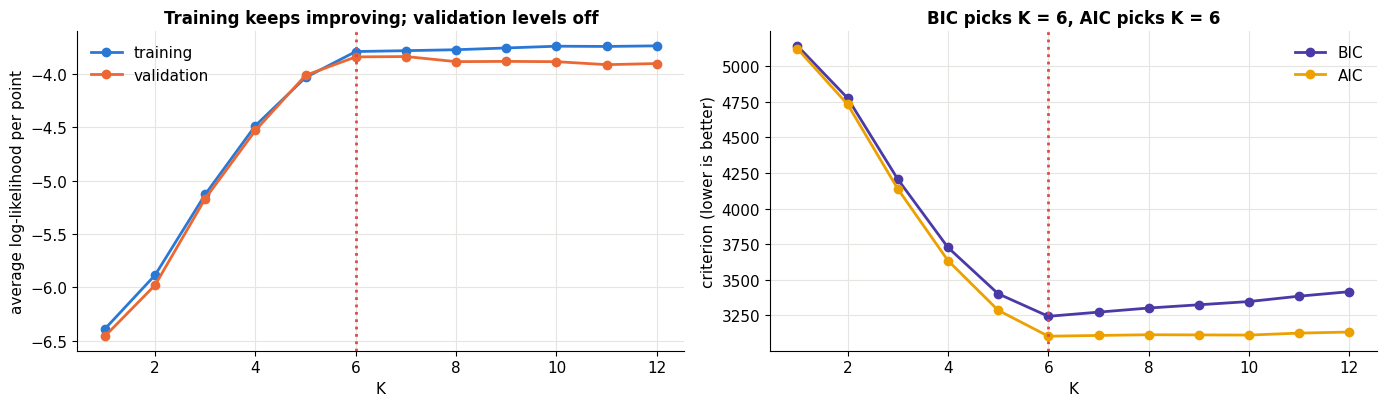

In [16]:
X_tr, X_va = X6[:400], X6[400:]
rows = []
for K in range(1, 13):
    gm = GaussianMixture(K, n_init=5, random_state=0).fit(X_tr)
    rows.append(dict(K=K, train=gm.score(X_tr), validation=gm.score(X_va), BIC=gm.bic(X_tr), AIC=gm.aic(X_tr)))
sel = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(sel.K, sel.train, "o-", label="training"); axes[0].plot(sel.K, sel.validation, "o-", label="validation")
axes[0].axvline(6, color=C["red"], ls=":"); axes[0].set(xlabel="K", ylabel="average log-likelihood per point", title="Training keeps improving; validation levels off"); axes[0].legend()
axes[1].plot(sel.K, sel.BIC, "o-", color=C["violet"], label="BIC"); axes[1].plot(sel.K, sel.AIC, "o-", color=C["yellow"], label="AIC")
axes[1].axvline(6, color=C["red"], ls=":"); axes[1].set(xlabel="K", ylabel="criterion (lower is better)", title=f"BIC picks K = {sel.K[sel.BIC.idxmin()]}, AIC picks K = {sel.K[sel.AIC.idxmin()]}"); axes[1].legend()
fig.tight_layout(); plt.show()

The data has 6 true clusters (red dotted line). The validation curve stops improving around there, and BIC's minimum is at or near it. AIC's lighter penalty tends to allow a few extra components. As with $k$ in k-means, these are guides: two touching blobs can legitimately be "one component".

---
## 10. What a fitted GMM is good for

A GMM is a full probability model $p(x)$, so it can do more than cluster.

**Soft clustering with uncertainty.** The responsibilities say how *sure* each assignment is. Points between components get split responsibilities, which is information k-means throws away.

**Density estimation and anomaly detection.** $p(x)$ is small where data is rare. Flag points whose log-density falls below, say, the 1st percentile of the training data's (notebook 18 develops this).

**Generating new data.** Run the generative story: pick a component, sample its Gaussian. Here's that idea applied to handwritten digits: reduce the 64-pixel images to 30 numbers with PCA (the subject of notebook 16), fit a GMM there, sample new points, and map them back to pixels.

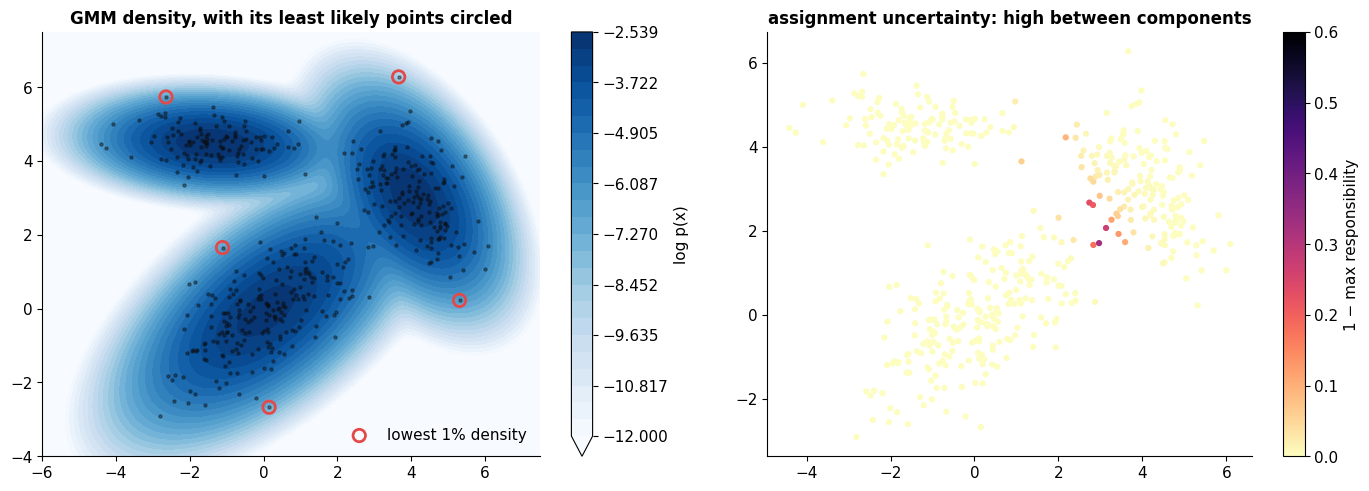

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
gm2 = GaussianMixture(3, n_init=5, random_state=0).fit(X)
gx, gy = np.meshgrid(np.linspace(-6, 7.5, 250), np.linspace(-4, 7.5, 250))
logdens = gm2.score_samples(np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
cs = axes[0].contourf(gx, gy, logdens, levels=np.linspace(-12, logdens.max(), 25), cmap="Blues", extend="min"); plt.colorbar(cs, ax=axes[0], label="log p(x)")
thresh = np.percentile(gm2.score_samples(X), 1)
out_pts = X[gm2.score_samples(X) < thresh]
axes[0].scatter(*X.T, s=5, color=C["ink"], alpha=0.4); axes[0].scatter(*out_pts.T, s=80, facecolors="none", edgecolors=C["red"], lw=2, label="lowest 1% density")
axes[0].set(aspect="equal", title="GMM density, with its least likely points circled"); axes[0].legend(loc="lower right"); axes[0].grid(False)
unc = 1 - gm2.predict_proba(X).max(1)
sc = axes[1].scatter(*X.T, s=12, c=unc, cmap="magma_r", vmin=0, vmax=0.6); plt.colorbar(sc, ax=axes[1], label="1 − max responsibility")
axes[1].set(aspect="equal", title="assignment uncertainty: high between components"); axes[1].grid(False)
fig.tight_layout(); plt.show()

BIC over K = [5, 10, 15, 20, 30, 40, 60] picks K = 10


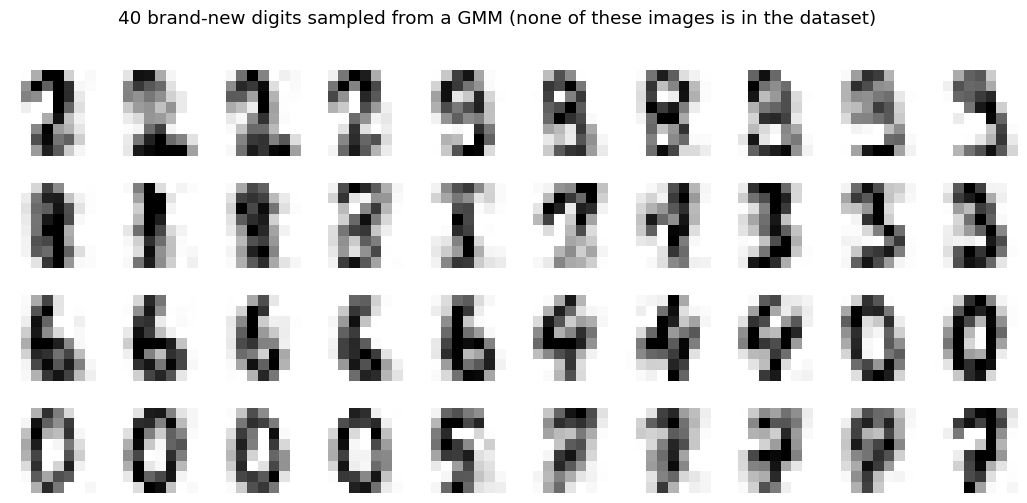

In [18]:
digits = load_digits(); Xdg = digits.data
pca = PCA(30, whiten=True, random_state=0).fit(Xdg); Zdg = pca.transform(Xdg)
bic = {K: GaussianMixture(K, covariance_type="full", random_state=0).fit(Zdg).bic(Zdg) for K in [5, 10, 15, 20, 30, 40, 60]}
K_best = min(bic, key=bic.get)
gm_dg = GaussianMixture(K_best, covariance_type="full", random_state=0).fit(Zdg)
new = pca.inverse_transform(gm_dg.sample(40)[0])
print(f"BIC over K = {list(bic)} picks K = {K_best}")
fig, axes = plt.subplots(4, 10, figsize=(13, 5.6))
for ax, img in zip(axes.ravel(), new):
    ax.imshow(np.clip(img, 0, 16).reshape(8, 8), cmap="gray_r"); ax.axis("off")
fig.suptitle("40 brand-new digits sampled from a GMM (none of these images is in the dataset)", y=0.98); plt.show()

Most samples are recognizable digits, some are smudgy in-betweens. A GMM is a respectable generative model for tiny images, but its components are fixed Gaussian blobs in a fixed linear space. Deep generative models (VAEs in notebook 23) replace the mixture's discrete hidden label with a continuous hidden vector and the linear map with a neural network, and they're trained with the same ELBO we derived in section 6.

---
## 11. EM beyond Gaussians: the two-coin problem

EM works for any model with hidden variables where the complete-data problem is easy. A classic illustration (Do & Batzoglou, 2008): there are two coins A and B with unknown heads probabilities $\theta_A, \theta_B$. Five times, someone picks one coin (we don't see which) and flips it 10 times. We only see the heads counts.

- **E-step:** for each set of 10 flips, compute the probability it came from coin A vs. B under the current $\theta$'s (binomial likelihoods, equal prior).
- **M-step:** $\theta_A = \frac{\text{expected heads attributed to A}}{\text{expected flips attributed to A}}$, likewise for B.

In [19]:
heads = np.array([5, 9, 8, 4, 7]); n_flip = 10
tA, tB = 0.6, 0.5
rows = []
for t in range(12):
    lA = tA ** heads * (1 - tA) ** (n_flip - heads); lB = tB ** heads * (1 - tB) ** (n_flip - heads)
    wA = lA / (lA + lB)                                        # E-step: P(coin A | this set of flips)
    rows.append(dict(iteration=t, theta_A=round(tA, 4), theta_B=round(tB, 4), **{f"P(A|set {i + 1})": round(w, 2) for i, w in enumerate(wA)}))
    tA = (wA * heads).sum() / (wA * n_flip).sum()              # M-step: weighted fraction of heads
    tB = ((1 - wA) * heads).sum() / ((1 - wA) * n_flip).sum()
pd.DataFrame(rows).set_index("iteration")

,theta_A,theta_B,P(A|set 1),P(A|set 2),P(A|set 3),P(A|set 4),P(A|set 5)
iteration,,,,,,,
0,0.6000,0.5000,0.45,0.80,0.73,0.35,0.65
1,0.7130,0.5813,0.30,0.81,0.71,0.19,0.57
2,0.7453,0.5693,0.22,0.87,0.75,0.11,0.58
3,0.7681,0.5495,0.16,0.91,0.79,0.07,0.59
4,0.7832,0.5346,0.13,0.94,0.82,0.04,0.59
5,0.7911,0.5263,0.11,0.95,0.84,0.04,0.60
6,0.7945,0.5224,0.11,0.95,0.84,0.03,0.60
7,0.7959,0.5207,0.10,0.95,0.84,0.03,0.60
8,0.7965,0.5200,0.10,0.95,0.84,0.03,0.60


Starting from $\theta_A = 0.6$, $\theta_B = 0.5$, EM settles on one coin that lands heads about 80% of the time (credited with the 9-, 8- and 7-head sets) and one fair-ish coin (the 5- and 4-head sets). The structure is identical to the GMM: soft-assign each observation to a hidden source, then refit each source with weighted counts. Hidden Markov models (speech, biology), topic models (documents), missing-data imputation, and mixtures of anything are all trained this way.

---
## 12. Summary

| | k-means | GMM + EM |
|---|---|---|
| Model | none (just an objective) | $p(x) = \sum_k \pi_k\mathcal{N}(x\mid\mu_k,\Sigma_k)$ |
| Assignment | hard: nearest center | soft: responsibilities $\gamma_{ik} = p(z{=}k\mid x^i)$ |
| Update | mean of assigned points | weighted $\pi_k, \mu_k, \Sigma_k$ |
| Cluster shapes | equal round balls | ellipses with own shape, size, weight |
| Objective | within-cluster variance (decreases) | log-likelihood (increases) |
| Relationship | hard EM, $\sigma \to 0$ limit | soft k-means |
| Pitfalls | local minima | local maxima, collapsing components |
| Extras | — | densities, uncertainty, sampling, BIC |

**EM in one sentence:** when a model would be easy to fit *if only* you knew some hidden variables, alternate between computing their posterior under the current model (E) and fitting the model with those soft values filled in (M); each round raises a lower bound that touches the log-likelihood, so the log-likelihood never decreases.

### ✏️ Exercises

1. Derive the M-step update for $\mu_k$ by setting the gradient of $\sum_i\sum_k\gamma_{ik}\log\big(\pi_k\mathcal{N}(x^i\mid\mu_k,\Sigma_k)\big)$ to zero. Then derive $\pi_k = N_k/m$ using a Lagrange multiplier for $\sum_k\pi_k = 1$ (notebook 03).
2. Prove the identity $\log p(x\mid\theta) = \mathcal{L}(q,\theta) + \mathrm{KL}(q\,\|\,p(z\mid x,\theta))$ from the definitions.
3. Implement **hard EM** (replace γ by one-hot argmax) for a GMM with full covariances. How does it behave on the "different spreads" data compared with soft EM and k-means?
4. Run `em_gmm` with `reg=0` and 15 components on 40 points. Watch the log-likelihood and the smallest covariance eigenvalue per iteration. What happens?
5. Change the two-coin example to start at $\theta_A = \theta_B = 0.5$. What does EM do, and why? (Hint: symmetry.)
6. Fit GMMs with `covariance_type="diag"` and `"full"` to the 30-D digit features and compare their BIC and the quality of sampled digits.

### References

- CX 4240 lectures 15–16 (density estimation, MLE of Gaussians, Gaussian mixture models, connection to Gaussian naive Bayes, EM, k-means vs. GMM) and the course GMM/EM cheat-sheet pattern.
- A. Dempster, N. Laird & D. Rubin, *Maximum Likelihood from Incomplete Data via the EM Algorithm*, JRSS-B (1977).
- R. Neal & G. Hinton, *A view of the EM algorithm that justifies incremental, sparse, and other variants* (1998): the free-energy/ELBO view used in section 6.
- C. Do & S. Batzoglou, *What is the expectation maximization algorithm?*, Nature Biotechnology (2008): the two-coin example.
- C. Bishop, *Pattern Recognition and Machine Learning*, Chapter 9.
- G. Schwarz, *Estimating the Dimension of a Model*, Annals of Statistics (1978) (BIC).

**Next → [16 · Principal Component Analysis](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/16_pca.ipynb)**